# OpenCV 课程环境自检
选择 **Python (OpenCV Course)** 内核，然后点击“运行全部”。以下单元格应全部成功，最后显示原图、灰度图和边缘图。

In [4]:
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
print("Python:", sys.executable)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
assert "opencv-course" in sys.executable.lower()

Python: d:\anaconda\envs\opencv-course\python.exe
OpenCV: 4.10.0
NumPy: 1.26.4


## Notebook 内联显示
`%matplotlib inline` 只写在 Notebook 单元格中；普通 `.py` 文件使用 `plt.show()`。

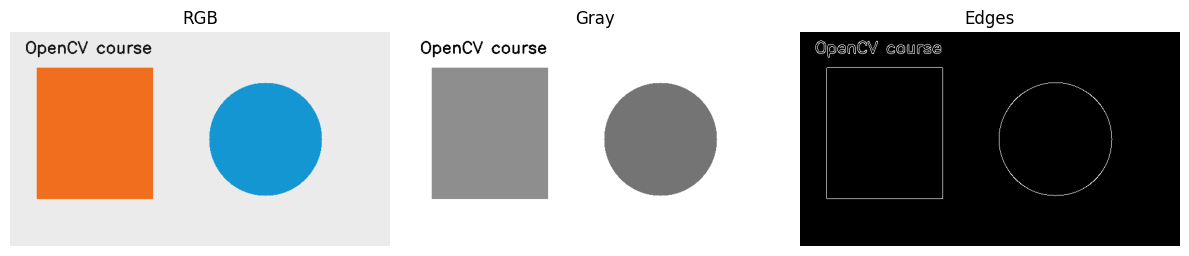

In [5]:
%matplotlib inline
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent
path = root / "data" / "sample.png"
img = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
assert img is not None
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 80, 160)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(axes, [cv2.cvtColor(img, cv2.COLOR_BGR2RGB), gray, edges], ["RGB", "Gray", "Edges"]):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 常用算法和中文路径验证

In [6]:
p = root / "data" / "中文路径测试.png"
assert cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_COLOR) is not None
contours = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
keypoints, descriptors = cv2.SIFT_create().detectAndCompute(gray, None)
print("Contours:", len(contours), "SIFT keypoints:", len(keypoints))
print("ALL CHECKS PASSED")

Contours: 15 SIFT keypoints: 123
ALL CHECKS PASSED
